In [1]:
from pathlib import Path
import polars as pl
import plotly.express as px
import plotly.graph_objects as go

# Raíz del proyecto = la carpeta que contiene pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pl.read_parquet(PROC / "m5_CA_1.parquet")
print("df:", df.shape, "| raíz:", ROOT)

df: (4788267, 18) | raíz: /Users/hectormm/m5-demand-inventory


In [2]:
sb = (
    df.group_by("id")
    .agg(
        n=pl.len(),
        nz=(pl.col("sales") > 0).sum(),
        mean_nz=pl.col("sales").filter(pl.col("sales") > 0).mean(),
        std_nz=pl.col("sales").filter(pl.col("sales") > 0).std(),
        revenue=(pl.col("sales") * pl.col("sell_price")).sum(),
    )
    .filter(pl.col("nz") > 1)
    .with_columns(adi=pl.col("n") / pl.col("nz"),
                  cv2=(pl.col("std_nz") / pl.col("mean_nz")) ** 2)
    .with_columns(
        sb_class=pl.when((pl.col("adi") < 1.32) & (pl.col("cv2") < 0.49)).then(pl.lit("smooth"))
        .when(pl.col("adi") < 1.32).then(pl.lit("erratic"))
        .when(pl.col("cv2") < 0.49).then(pl.lit("intermittent"))
        .otherwise(pl.lit("lumpy"))
    )
)
print(sb["sb_class"].value_counts().sort("count", descending=True))

shape: (4, 2)
┌──────────────┬───────┐
│ sb_class     ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ intermittent ┆ 2195  │
│ lumpy        ┆ 546   │
│ smooth       ┆ 232   │
│ erratic      ┆ 76    │
└──────────────┴───────┘


In [3]:
# ABC por ingreso acumulado: A ≤ 80%, B ≤ 95%, C resto
sb = (
    sb.sort("revenue", descending=True)
    .with_columns(cum_share=pl.col("revenue").cum_sum() / pl.col("revenue").sum())
    .with_columns(abc=pl.when(pl.col("cum_share") <= 0.80).then(pl.lit("A"))
                  .when(pl.col("cum_share") <= 0.95).then(pl.lit("B"))
                  .otherwise(pl.lit("C")))
)

# XYZ por CV de la demanda semanal: X < 0.5, Y < 1.0, Z resto
xyz = (
    df.group_by(["id", "wm_yr_wk"]).agg(pl.col("sales").sum())
    .group_by("id").agg(cv_w=pl.col("sales").std() / pl.col("sales").mean())
    .with_columns(xyz=pl.when(pl.col("cv_w") < 0.5).then(pl.lit("X"))
                  .when(pl.col("cv_w") < 1.0).then(pl.lit("Y"))
                  .otherwise(pl.lit("Z")))
)

seg = sb.join(xyz, on="id", how="left")
seg.write_parquet(PROC / "segmentacion_CA_1.parquet")

print(seg.group_by(["abc", "xyz"]).len().sort(["abc", "xyz"]))

shape: (9, 3)
┌─────┬─────┬─────┐
│ abc ┆ xyz ┆ len │
│ --- ┆ --- ┆ --- │
│ str ┆ str ┆ u32 │
╞═════╪═════╪═════╡
│ A   ┆ X   ┆ 292 │
│ A   ┆ Y   ┆ 815 │
│ A   ┆ Z   ┆ 110 │
│ B   ┆ X   ┆ 64  │
│ B   ┆ Y   ┆ 680 │
│ B   ┆ Z   ┆ 181 │
│ C   ┆ X   ┆ 18  │
│ C   ┆ Y   ┆ 381 │
│ C   ┆ Z   ┆ 508 │
└─────┴─────┴─────┘


In [4]:
def guardar(fig, nombre):
    fig.write_html(FIG_DIR / f"{nombre}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(FIG_DIR / f"{nombre}.png", width=1100, height=600, scale=2)
    except Exception as e:
        print(f"PNG no generado ({e}); el HTML sí se guardó.")
    fig.show()

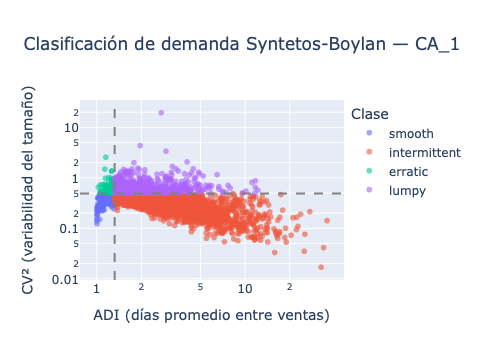

In [5]:
fig = px.scatter(
    seg.to_pandas(), x="adi", y="cv2", color="sb_class",
    hover_data=["id", "abc", "xyz"], opacity=0.6, log_x=True, log_y=True,
    labels={"adi": "ADI (días promedio entre ventas)", "cv2": "CV² (variabilidad del tamaño)",
            "sb_class": "Clase"},
    title="Clasificación de demanda Syntetos-Boylan — CA_1",
)
fig.add_vline(x=1.32, line_dash="dash", line_color="gray")
fig.add_hline(y=0.49, line_dash="dash", line_color="gray")
guardar(fig, "01_adi_cv2")

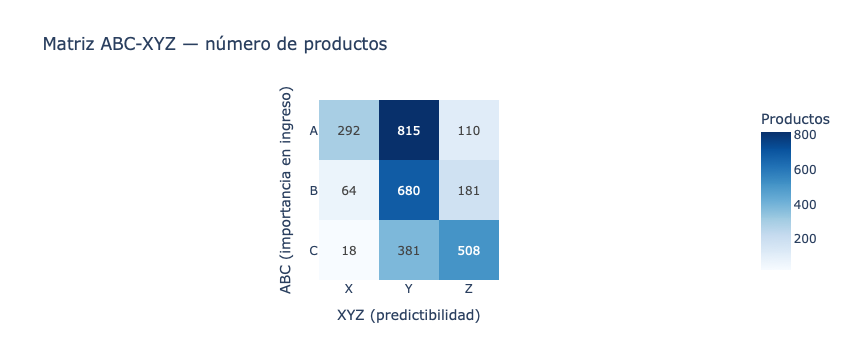

In [6]:
mat = (seg.group_by(["abc", "xyz"]).len()
          .to_pandas()
          .pivot(index="abc", columns="xyz", values="len")
          .reindex(index=["A", "B", "C"], columns=["X", "Y", "Z"])
          .fillna(0).astype(int))

fig = px.imshow(mat, text_auto=True, color_continuous_scale="Blues",
                labels=dict(x="XYZ (predictibilidad)", y="ABC (importancia en ingreso)",
                            color="Productos"),
                title="Matriz ABC-XYZ — número de productos")
guardar(fig, "02_abc_xyz")

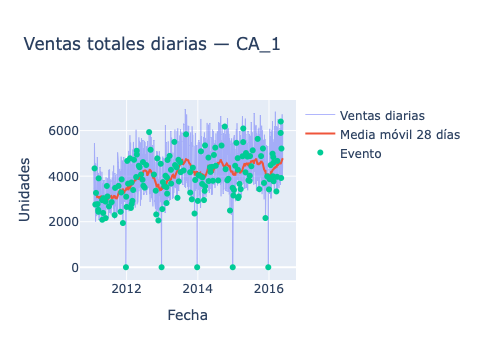

In [7]:
diario = (df.group_by("date")
            .agg(ventas=pl.col("sales").sum(),
                 evento=pl.col("event_name_1").first().cast(pl.Utf8))
            .sort("date")
            .with_columns(media_28=pl.col("ventas").rolling_mean(28))
            .to_pandas())

ev = diario[diario["evento"] != "none"]

fig = go.Figure()
fig.add_scatter(x=diario["date"], y=diario["ventas"], name="Ventas diarias",
                line=dict(width=1), opacity=0.5)
fig.add_scatter(x=diario["date"], y=diario["media_28"], name="Media móvil 28 días",
                line=dict(width=2))
fig.add_scatter(x=ev["date"], y=ev["ventas"], mode="markers", name="Evento",
                marker=dict(size=6), text=ev["evento"], hovertemplate="%{text}<br>%{y}")
fig.update_layout(title="Ventas totales diarias — CA_1",
                  xaxis_title="Fecha", yaxis_title="Unidades")
guardar(fig, "03_ventas_diarias")

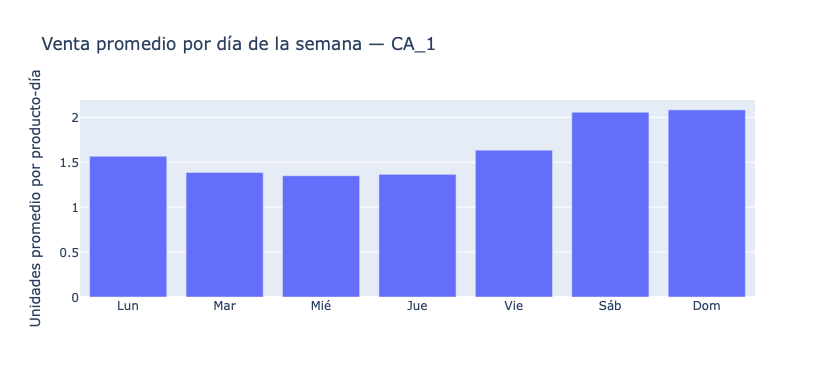

In [8]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

por_dia = (df.with_columns(dia=pl.col("date").dt.weekday())   # 1 = lunes … 7 = domingo
             .group_by("dia").agg(venta_media=pl.col("sales").mean())
             .sort("dia").to_pandas())
por_dia["dia"] = por_dia["dia"].map(lambda d: dias[d - 1])

fig = px.bar(por_dia, x="dia", y="venta_media",
             labels={"dia": "", "venta_media": "Unidades promedio por producto-día"},
             title="Venta promedio por día de la semana — CA_1")
guardar(fig, "04a_dia_semana")

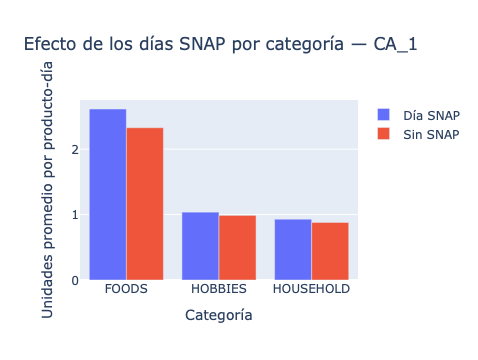

In [21]:
por_snap = (df.group_by(["cat_id", "snap"])
              .agg(venta_media=pl.col("sales").mean())
              .with_columns(pl.col("cat_id").cast(pl.Utf8),
                            snap=pl.when(pl.col("snap") == 1).then(pl.lit("Día SNAP"))
                                   .otherwise(pl.lit("Sin SNAP")))
              .sort("cat_id").to_pandas())

fig = px.bar(por_snap, x="cat_id", y="venta_media", color="snap", barmode="group",
             labels={"cat_id": "Categoría", "venta_media": "Unidades promedio por producto-día",
                     "snap": ""},
             title="Efecto de los días SNAP por categoría — CA_1")
guardar(fig, "04b_snap")

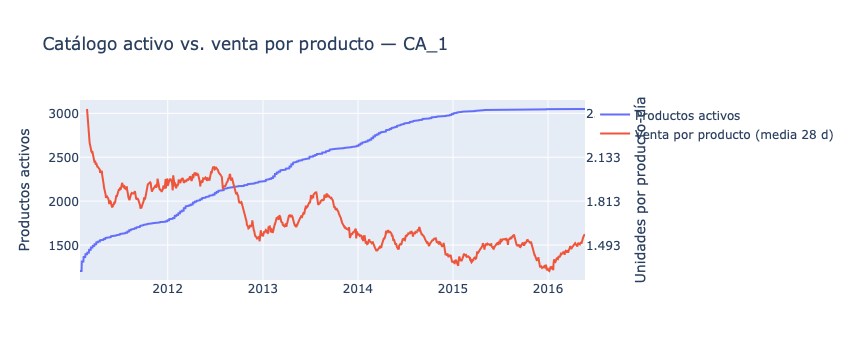

In [9]:
activos = (df.group_by("date")
             .agg(productos_activos=pl.col("id").n_unique(),
                  ventas=pl.col("sales").sum())
             .sort("date")
             .with_columns(venta_por_producto=pl.col("ventas") / pl.col("productos_activos"))
             .with_columns(pl.col("venta_por_producto").rolling_mean(28).alias("vpp_28"))
             .to_pandas())

fig = go.Figure()
fig.add_scatter(x=activos["date"], y=activos["productos_activos"], name="Productos activos", yaxis="y1")
fig.add_scatter(x=activos["date"], y=activos["vpp_28"], name="Venta por producto (media 28 d)", yaxis="y2")
fig.update_layout(title="Catálogo activo vs. venta por producto — CA_1",
                  yaxis=dict(title="Productos activos"),
                  yaxis2=dict(title="Unidades por producto-día", overlaying="y", side="right"))
guardar(fig, "05_catalogo_vs_venta")

In [10]:
## Hallazgos del EDA — CA_1

#1. **La demanda intermitente domina el catálogo.** La mayoría de los productos venden con días sin venta de por medio; en los muy esporádicos, la incertidumbre está en *cuándo* se vende, no en *cuánto*.
#2. **El ingreso está poco concentrado:** el 40% de los productos genera el 80% del ingreso, y solo el 12% tiene demanda semanal predecible (X). El segmento AZ (110 productos importantes y erráticos) concentra el mayor riesgo de faltantes.
#3. **El crecimiento de ventas es expansión del catálogo, no de la demanda:** las ventas totales suben ~50% entre 2011 y 2016, pero el catálogo activo creció ~2.5× y la venta por producto *bajó* ~30%. Los productos nuevos venden menos que los originales. El catálogo se estabiliza desde abril de 2015.
#4. **Estacionalidad anual clara a nivel producto:** la venta por producto toca su mínimo cada diciembre-enero y sube hacia mitad de año; en las ventas totales la expansión del catálogo ocultaba este patrón.
#5. **La estacionalidad semanal es la señal más fuerte:** sábado y domingo venden ~52% más que de martes a jueves.
#6. **Los eventos aportan poco salvo excepciones:** la tienda cierra cada 25 de diciembre (ventas = 0, se excluye) y Acción de Gracias reduce las ventas entre 40% y 50%.
#7. **El efecto SNAP está confundido con el inicio de mes:** FOODS sube ~12% en días SNAP, pero las categorías no elegibles también suben ~5–6%, lo que sugiere un efecto de ingreso a inicio de mes.